# house prices in sri lanka

goal is to predict the asking price of a house for sale in sri lanka. data is the ikman.lk property ads dataset from kaggle (ivantha). this notebook covers getting the data, cleaning it and a first look. modelling is in the next notebook.

In [1]:
import os, io, glob, ast, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

## 1. getting the data

downloaded with kagglehub into `../data/raw`. that folder is ignored by git, only the cleaned file gets saved in the repo.

In [2]:
os.environ['KAGGLEHUB_CACHE'] = '../data/raw'
import kagglehub

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    kagglehub.dataset_download('ivantha/sri-lanka-property-ads-dataset')

csv_path = glob.glob('../data/raw/**/properties.csv', recursive=True)[0]
raw = pd.read_csv(csv_path)
print(raw.shape)

(203874, 26)


In [3]:
raw[['category', 'type']].value_counts().head(8)

category                     type    
Land For Sale                for_sale    82123
Houses For Sale              for_sale    51890
Land                         for_sale    27046
House Rentals                for_rent    14754
Apartment Rentals            for_rent     7164
Apartments For Sale          for_sale     5177
Commercial Property Rentals  for_rent     4415
Room & Annex Rentals         for_rent     4373
Name: count, dtype: int64

the file has everything people post under property: land, houses, apartments, rentals and commercial. land is often priced per perch and rentals per month, so those prices cannot sit in one target column. i keep only **houses for sale** (52,193 ads), where the price is the full asking price in rupees.

In [4]:
houses = raw[raw['category'] == 'Houses For Sale'].copy()
print(houses.shape)
houses[['price', 'details', 'location', 'properties']].head()

(52193, 26)


,price,details,location,properties
4,"Rs 55,000,000","Bedrooms: 5, Bathrooms: 4",Kadawatha,"{'Address': 'Pinthaliya Road, Kadawatha', 'Bed..."
9,"Rs 80,000,000","Bedrooms: 4, Bathrooms: 4",Dehiwala,"{'Address': 'kadawatha Road', 'Bedrooms': '4',..."
21,"Rs 125,000,000","Bedrooms: 4, Bathrooms: 2",Mount Lavinia,"{'Address': 'Off Temple Road, Mount Lavinia', ..."
22,"Rs 58,000,000","Bedrooms: 4, Bathrooms: 3",Malabe,"{'Bedrooms': '4', 'Bathrooms': '3', 'House siz..."
24,"Rs 22,000,000","Bedrooms: 4, Bathrooms: 3",Kotte,"{'Address': 'Kotte', 'Bedrooms': '4', 'Bathroo..."


## 2. parsing the text columns

the useful details (bedrooms, bathrooms, house size, land size) are all inside a dictionary string in `properties`. price is text like `Rs 38,000,000`, and the district is inside the `area` string. pulled these out into proper columns.

In [5]:
def parse_dict(s):
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return {}

props = houses['properties'].apply(parse_dict)

def first_number(text):
    # grabs the number from strings like '3,500.0 sqft'
    if pd.isna(text):
        return np.nan
    cleaned = str(text).replace(',', '').split(' ')[0]
    return pd.to_numeric(cleaned, errors='coerce')

df = pd.DataFrame({
    'price': houses['price'].str.replace(r'[^0-9]', '', regex=True).pipe(pd.to_numeric, errors='coerce'),
    'bedrooms': props.apply(lambda d: first_number(d.get('Bedrooms'))),
    'bathrooms': props.apply(lambda d: first_number(d.get('Bathrooms'))),
    'house_size_sqft': props.apply(lambda d: first_number(d.get('House size'))),
    'land_size_perches': props.apply(lambda d: first_number(d.get('Land size'))),
    'location': houses['location'].str.strip().str.title(),
    'district': houses['area'].apply(lambda s: parse_dict(s).get('name')),
    'membership_level': houses['membership_level'],
    'is_verified': houses['is_verified'].astype(int),
    'is_member': houses['is_member'],
    'posted_date': pd.to_datetime(houses['posted_date'], utc=True, errors='coerce'),
}).reset_index(drop=True)
df['posted_month'] = df['posted_date'].dt.month
df = df.drop(columns='posted_date')
df.head()

,price,bedrooms,bathrooms,house_size_sqft,land_size_perches,location,district,membership_level,is_verified,is_member,posted_month
0,55000000.0,5.0,4.0,3000.0,27.50,Kadawatha,Gampaha,premium,1,True,1.0
1,80000000.0,4.0,4.0,3000.0,8.75,Dehiwala,Colombo,premium,1,True,2.0
2,125000000.0,4.0,2.0,5600.0,20.00,Mount Lavinia,Colombo,premium,1,True,1.0
3,58000000.0,4.0,3.0,4000.0,16.00,Malabe,Colombo,premium,1,True,1.0
4,22000000.0,4.0,3.0,2200.0,6.50,Kotte,Colombo,premium,0,True,10.0


## 3. nulls and duplicates

nulls are small. the biggest one is `is_member` at 2.6%, the rest are under 1%.

In [6]:
df.isna().sum().to_frame('nulls').assign(pct=lambda x: (x['nulls'] / len(df) * 100).round(2))

,nulls,pct
price,305,0.58
bedrooms,425,0.81
bathrooms,357,0.68
house_size_sqft,303,0.58
land_size_perches,303,0.58
location,0,0.00
district,0,0.00
membership_level,0,0.00
is_verified,0,0.00
is_member,1375,2.63


In [7]:
print('duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('rows after dropping duplicates:', len(df))

duplicate rows: 15558
rows after dropping duplicates: 36635


15,558 exact duplicates went already. but sellers also repost the same house with a new date or a different membership flag, so those are not exact copies. if a house is in train and its repost is in test, the test score would look better than it should. so houses with the same price, specs and location count as reposts and i keep one. that removed another 7,937 rows.

In [8]:
core = ['price', 'bedrooms', 'bathrooms', 'house_size_sqft', 'land_size_perches', 'location']
print('reposts:', df.duplicated(core).sum())
df = df.drop_duplicates(core).reset_index(drop=True)
print('rows after removing reposts:', len(df))

reposts: 7937
rows after removing reposts: 28698


305 ads have no price, so they cannot be used for training. i drop them. missing bedrooms, bathrooms and sizes stay for now, i will fill those inside the model pipeline so the fill values come from the training data only.

In [9]:
df = df.dropna(subset=['price']).reset_index(drop=True)
df.describe().round(1)

,price,bedrooms,bathrooms,house_size_sqft,land_size_perches,is_verified,posted_month
count,2.861900e+04,28531.0,28582.0,28619.0,28619.0,28619.0,28616.0
mean,6.713745e+07,3.7,2.5,2621.7,24.3,0.6,5.7
std,5.320072e+09,1.3,1.3,7442.6,451.4,0.5,4.6
min,7.000000e+00,1.0,1.0,0.0,0.0,0.0,1.0
25%,1.280000e+07,3.0,1.0,1452.0,7.5,0.0,2.0
50%,2.450000e+07,4.0,2.0,2100.0,10.0,1.0,3.0
75%,4.000000e+07,4.0,3.0,3000.0,14.5,1.0,11.0
max,9.000000e+11,10.0,10.0,900000.0,62500.0,1.0,12.0


## 4. outliers

the describe table has values that cannot be real. the lowest price is rs 7, the highest is rs 900 billion, one house is 900,000 sqft and one plot is 62,500 perches. these look like typing mistakes (extra or missing zeros).

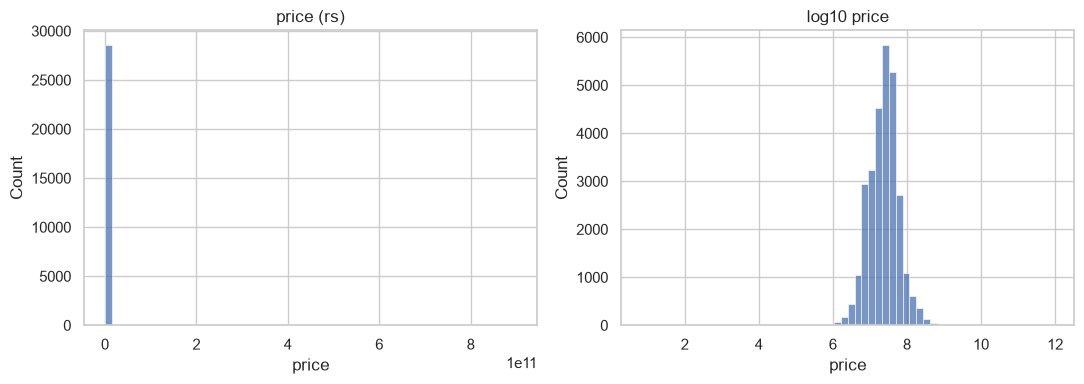

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['price'], bins=60, ax=ax[0])
ax[0].set_title('price (rs)')
sns.histplot(np.log10(df['price']), bins=60, ax=ax[1])
ax[1].set_title('log10 price')
plt.tight_layout()
plt.show()

price is heavily right skewed, most houses are between 10 and 50 million but a few are far above. on the log scale it looks much closer to normal, so i will model `log(price)`. there is also a bump of very cheap ads on the left.

cut the price at the 1st and 99th percentile (about rs 2.5 million to 230 million) and kept only realistic sizes: 1 to 10 bedrooms and bathrooms, 200 to 20,000 sqft, 1 to 500 perches. 896 rows removed, 27,723 left.

In [11]:
print(df['price'].quantile([0, .005, .01, .05, .5, .95, .99, .995, 1]).round(0))

0.000    7.000000e+00
0.005    1.600000e+06
0.010    2.500000e+06
0.050    5.200000e+06
0.500    2.450000e+07
0.950    1.000000e+08
0.990    2.300000e+08
0.995    3.070000e+08
1.000    9.000000e+11
Name: price, dtype: float64

In [12]:
for col in ['bedrooms', 'bathrooms', 'house_size_sqft', 'land_size_perches']:
    print(col, df[col].quantile([0, .01, .5, .99, 1]).round(1).tolist())

bedrooms [1.0, 1.0, 4.0, 8.0, 10.0]
bathrooms [1.0, 1.0, 2.0, 6.0, 10.0]
house_size_sqft [0.0, 400.0, 2100.0, 10000.0, 900000.0]
land_size_perches [0.0, 2.0, 10.0, 100.0, 62500.0]


In [13]:
low, high = df['price'].quantile([.01, .99])
before = len(df)

keep = df['price'].between(low, high)
keep &= df['bedrooms'].between(1, 10) | df['bedrooms'].isna()
keep &= df['bathrooms'].between(1, 10) | df['bathrooms'].isna()
keep &= df['house_size_sqft'].between(200, 20000) | df['house_size_sqft'].isna()
keep &= df['land_size_perches'].between(1, 500) | df['land_size_perches'].isna()

df = df[keep].reset_index(drop=True)
print(f'removed {before - len(df)} rows, kept {len(df)}')

removed 896 rows, kept 27723


In [14]:
df.describe().round(1)

,price,bedrooms,bathrooms,house_size_sqft,land_size_perches,is_verified,posted_month
count,27723.0,27642.0,27690.0,27723.0,27723.0,27723.0,27720.0
mean,32706856.9,3.7,2.5,2416.2,13.6,0.6,5.7
std,31678266.0,1.3,1.3,1477.4,16.7,0.5,4.6
min,2500000.0,1.0,1.0,200.0,1.0,0.0,1.0
25%,13000000.0,3.0,1.0,1472.0,7.5,0.0,2.0
50%,24500000.0,4.0,2.0,2100.0,10.0,1.0,3.0
75%,40000000.0,4.0,3.0,3000.0,14.0,1.0,11.0
max,230000000.0,10.0,10.0,20000.0,480.0,1.0,12.0


## 5. looking at the relationships

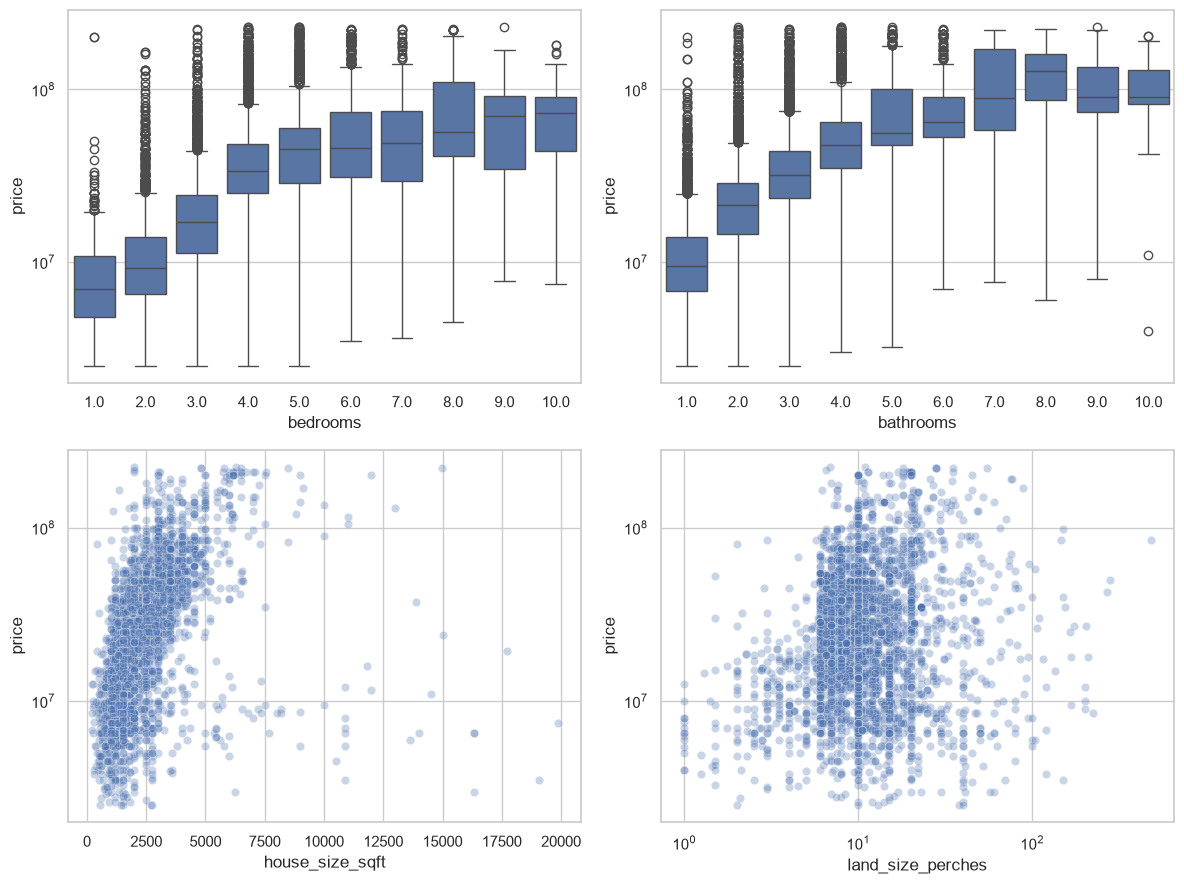

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
sns.boxplot(data=df, x='bedrooms', y='price', ax=ax[0, 0])
ax[0, 0].set_yscale('log')
sns.boxplot(data=df, x='bathrooms', y='price', ax=ax[0, 1])
ax[0, 1].set_yscale('log')
sns.scatterplot(data=df.sample(4000, random_state=1), x='house_size_sqft', y='price', alpha=.3, ax=ax[1, 0])
ax[1, 0].set_yscale('log')
sns.scatterplot(data=df.sample(4000, random_state=1), x='land_size_perches', y='price', alpha=.3, ax=ax[1, 1])
ax[1, 1].set_xscale('log')
ax[1, 1].set_yscale('log')
plt.tight_layout()
plt.show()

price rises with bedrooms, bathrooms and house size, as expected. land size is much noisier. a small plot in colombo costs more than a big plot in a village, so location has to be doing a lot here.

In [16]:
district_price = df.groupby('district')['price'].agg(['count', 'median']).sort_values('median', ascending=False)
district_price[district_price['count'] >= 30].round(0)

,count,median
district,,
Colombo,18083,28500000.0
Gampaha,4652,21500000.0
Kandy,927,19500000.0
Jaffna,55,14000000.0
Kalutara,1261,12700000.0
Matara,265,11500000.0
Nuwara Eliya,64,10250000.0
Kurunegala,471,10000000.0
Puttalam,139,10000000.0


In [17]:
top_locations = df['location'].value_counts()
print('distinct locations:', len(top_locations))
print('locations with under 20 ads:', (top_locations < 20).sum())
top_locations.head(10)

distinct locations: 202
locations with under 20 ads: 84


location
Piliyandala     5061
Kottawa         1140
Talawatugoda    1126
Negombo         1085
Homagama         949
Dehiwala         897
Athurugiriya     846
Malabe           769
Nugegoda         729
Wellampitiya     678
Name: count, dtype: int64

colombo has 18,083 of the 27,723 ads and gampaha 4,652. most districts have under 200 ads. median price drops fast outside the western province: colombo 28.5 million, gampaha 21.5 million, kandy 19.5 million, most others 8 to 12 million.

there are 202 locations and 84 of them have under 20 ads, so one hot encoding all of them would be very wide and mostly empty. i will group the rare ones in the pipeline. piliyandala alone has 5,061 ads (18% of the data), probably a few agents posting a lot there.

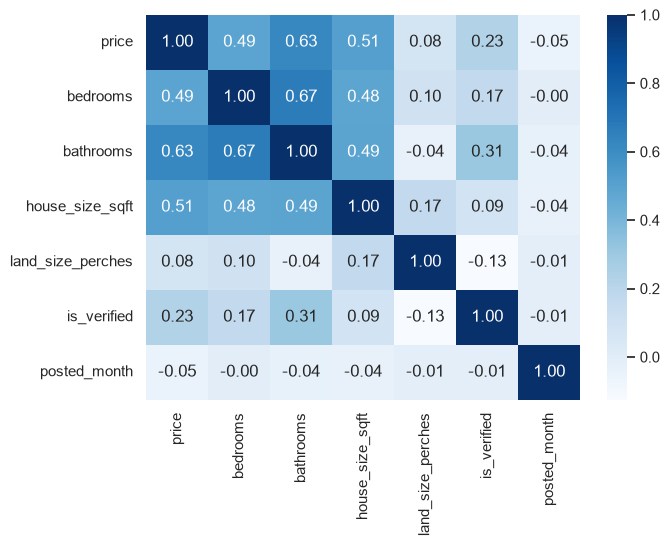

In [18]:
num_cols = ['price', 'bedrooms', 'bathrooms', 'house_size_sqft', 'land_size_perches', 'is_verified', 'posted_month']
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='Blues')
plt.show()

house size and bathrooms have the strongest link with price. posting month is almost flat, so i do not expect it to help.

## 6. saving the cleaned data

this file only has the cleaning (parsing, duplicates, reposts, outliers). imputing, encoding and scaling happen in the modelling notebook.

In [19]:
os.makedirs('../data/processed', exist_ok=True)
df.to_csv('../data/processed/houses_clean.csv', index=False)
print(df.shape)

(27723, 11)
